In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
%matplotlib inline

In [19]:
class charMLP(torch.nn.Module):
    def __init__(self, vocab_size, hidden_size, embedding_size, block_size):
        super().__init__()
        self.embedding = torch.nn.Embedding(vocab_size, embedding_size)
        self.flatten = torch.nn.Flatten()
        self.linear = torch.nn.Linear(embedding_size * block_size, hidden_size, bias=False)
        self.batchnorm = torch.nn.BatchNorm1d(hidden_size)
        self.tanh = torch.nn.Tanh()
        self.fc_out = torch.nn.Linear(hidden_size, vocab_size)
        self.net = torch.nn.Sequential(
            self.embedding, self.flatten, self.linear, self.batchnorm, self.tanh, self.fc_out
        )

    def forward(self, x):
        x = self.embedding(x)
        x = self.flatten(x)
        x = self.linear(x)
        x = self.batchnorm(x)
        x = self.tanh(x)
        x = self.fc_out(x)
        return x

In [25]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
batch_size = 64
block_size = 8
vocab_size = 27  # 26 letters + 1 for padding
hidden_size = 100
X = torch.randint(0, 27, (1000, block_size))
Y = torch.randint(0, 27, (1000,))
dataset = torch.utils.data.TensorDataset(X, Y)
loader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)
model = charMLP(vocab_size, hidden_size, embedding_size=10, block_size=block_size).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-1)
loss = torch.nn.CrossEntropyLoss()



In [26]:
lossi = []
model.train()
for epoch in range(40):
    total_loss = 0.0
    for Xb, Yb in loader:
        Xb, Yb = Xb.to(device), Yb.to(device)
        optimizer.zero_grad() 
        logits = model(Xb)
        loss_value = loss(logits, Yb)
        loss_value.backward()
        optimizer.step()
        total_loss += loss_value.item()
    lossi.append(total_loss/len(loader))
    print(f"Epoch {epoch}, Loss: {total_loss/len(loader)}")

Epoch 0, Loss: 4.0535848736763
Epoch 1, Loss: 3.5054036676883698
Epoch 2, Loss: 3.1582250893115997
Epoch 3, Loss: 2.9134216904640198
Epoch 4, Loss: 2.7854886204004288
Epoch 5, Loss: 2.663634553551674
Epoch 6, Loss: 2.6704436391592026
Epoch 7, Loss: 2.6028146371245384
Epoch 8, Loss: 2.4958260655403137
Epoch 9, Loss: 2.370140887796879
Epoch 10, Loss: 2.2582135796546936
Epoch 11, Loss: 2.2625349536538124
Epoch 12, Loss: 2.120224714279175
Epoch 13, Loss: 2.0673100724816322
Epoch 14, Loss: 2.0858827233314514
Epoch 15, Loss: 1.9013299457728863
Epoch 16, Loss: 1.904591128230095
Epoch 17, Loss: 1.6502132192254066
Epoch 18, Loss: 1.411726113408804
Epoch 19, Loss: 1.2229975275695324
Epoch 20, Loss: 1.1756529808044434
Epoch 21, Loss: 1.0643475949764252
Epoch 22, Loss: 1.015710886567831
Epoch 23, Loss: 0.8991016838699579
Epoch 24, Loss: 0.9600217547267675
Epoch 25, Loss: 0.9354359619319439
Epoch 26, Loss: 0.9168347921222448
Epoch 27, Loss: 0.8223849385976791
Epoch 28, Loss: 0.7501597180962563
Epoc

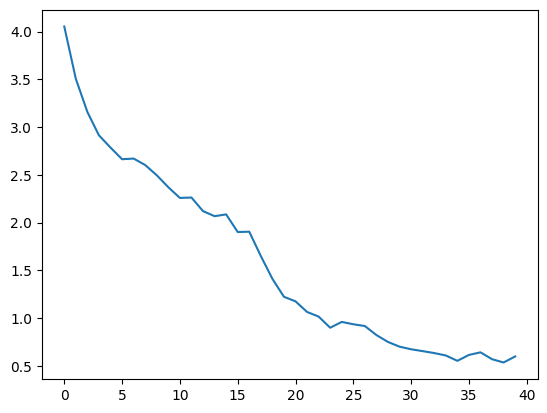

In [29]:
plt.plot(lossi)

In [35]:
# simple CNN
import torch
class CNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1, bias=False),
            torch.nn.BatchNorm2d(16),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),

            torch.nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1, bias=False),
            torch.nn.BatchNorm2d(32),
            torch.nn.ReLU(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),

            torch.nn.Flatten(),
            torch.nn.Linear(32 * 7 * 7, 10)
        )
    def forward(self, x):
        return self.net(x)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
X = torch.randn(1000, 1, 28, 28)
Y = torch.randint(0, 10, (1000,))
dataset = torch.utils.data.TensorDataset(X, Y)
loader = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=True)
CNN().to(device)
model = CNN().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
loss = torch.nn.CrossEntropyLoss()
model.train()
lossi = []
for epoch in range(19):
    tloss = 0
    for Xb, Yb in loader:
        Xb, Yb = Xb.to(device), Yb.to(device)
        optimizer.zero_grad()
        logits = model(Xb)
        loss_value = loss(logits, Yb)
        loss_value.backward()
        optimizer.step()
        tloss += loss_value.item()
    lossi.append(tloss / len(loader))
    print(f"Epoch {epoch}, Loss: {tloss/len(loader)}")

Epoch 0, Loss: 2.540275067090988
Epoch 1, Loss: 2.2049378156661987
Epoch 2, Loss: 2.046689987182617
Epoch 3, Loss: 1.8681692630052567
Epoch 4, Loss: 1.7083741500973701
Epoch 5, Loss: 1.5988401472568512
Epoch 6, Loss: 1.4543751776218414
Epoch 7, Loss: 1.297873392701149
Epoch 8, Loss: 1.1684808731079102
Epoch 9, Loss: 1.0534659214317799
Epoch 10, Loss: 0.9132106564939022
Epoch 11, Loss: 0.817342359572649
Epoch 12, Loss: 0.7173871360719204
Epoch 13, Loss: 0.6273849010467529
Epoch 14, Loss: 0.5452980548143387
Epoch 15, Loss: 0.463548356667161
Epoch 16, Loss: 0.40413326397538185
Epoch 17, Loss: 0.36598485335707664
Epoch 18, Loss: 0.3167807087302208


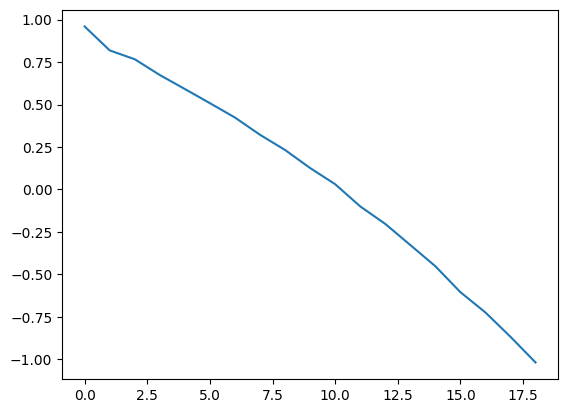

In [34]:
import matplotlib.pyplot as plt
lossi = torch.tensor(lossi)
plt.plot(lossi.log())